# Explainability (SHAP)

Explains the saved models; nothing is retrained.

| Model | Method | Explains |
|---|---|---|
| Attack classifier (Random Forest) | SHAP `TreeExplainer` | Probability of each attack class |
| Intrusion-risk (HistGradientBoosting under isotonic calibration) | SHAP `TreeExplainer` on the base model | Log-odds of "intrusion" (calibration is monotonic, so the ranking of reasons is unchanged) |
| Anomaly detector (Isolation Forest) | Benign percentiles | Which features are furthest from normal traffic |

**Global:** which traffic characteristics drive each attack type. **Local:** `explain_flow()` gives the reasons behind one prediction,
later reused by the ML service and the LLM agent.

In [1]:
import json
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from threadpoolctl import threadpool_limits

# Locate the repository root so the notebook runs from any checkout location.
PROJECT_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "requirements.txt").exists() and (p / "src").is_dir()
)

DATA_PATH = PROJECT_ROOT / "data" / "cleaned_network_data" / "cleaned_network_data.csv"
MODEL_DIR = PROJECT_ROOT / "ml" / "models"
FIG_DIR = PROJECT_ROOT / "ml" / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
ROWS_PER_CLASS = 150
TOP_K = 5

threadpool_limits(2)
print("shap", shap.__version__)

shap 0.48.0


## 1. Load models and data

In [2]:
clf = joblib.load(MODEL_DIR / "attack_classifier.pkl")
clf_meta = json.loads((MODEL_DIR / "attack_classifier_meta.json").read_text())

risk_model = joblib.load(MODEL_DIR / "intrusion_risk.pkl")
risk_meta = json.loads((MODEL_DIR / "intrusion_risk_meta.json").read_text())

anomaly_model = joblib.load(MODEL_DIR / "anomaly_detector.pkl")
anomaly_meta = json.loads((MODEL_DIR / "anomaly_detector_meta.json").read_text())

FEATURES = clf_meta["features"]
assert FEATURES == risk_meta["features"] == anomaly_meta["features"], "models must share the same feature order"

# The risk model is CalibratedClassifierCV(FrozenEstimator(HGB)); SHAP explains the HGB underneath.
risk_base = risk_model.calibrated_classifiers_[0].estimator.estimator
CLASSES = list(clf.classes_)

df = pd.read_csv(DATA_PATH).drop_duplicates(subset=FEATURES).reset_index(drop=True)
# SHAP explainers are built from the models (fast, nothing to save).
clf_explainer = shap.TreeExplainer(clf)
risk_explainer = shap.TreeExplainer(risk_base)

print("Rows after dedupe:", len(df))
print("Risk base model:", type(risk_base).__name__)

Rows after dedupe: 87222
Risk base model: HistGradientBoostingClassifier


## 2. Explanation sample

Up to 150 rows per traffic type (all rows for the rare classes). SHAP on all rows would be slow and add nothing.

In [3]:
sample = pd.concat(
    [g.sample(n=min(len(g), ROWS_PER_CLASS), random_state=RANDOM_STATE) for _, g in df.groupby("label")]
).reset_index(drop=True)
X_sample = sample[FEATURES]

print("Sample rows:", len(sample))
print(sample["label"].value_counts().to_string())

Sample rows: 1867
label
BENIGN                        150
Bot                           150
DDoS                          150
DoS GoldenEye                 150
DoS Hulk                      150
DoS Slowhttptest              150
DoS slowloris                 150
FTP-Patator                   150
PortScan                      150
Web Attack - Brute Force      150
SSH-Patator                   150
Web Attack - XSS              150
Infiltration                   36
Web Attack - Sql Injection     20
Heartbleed                     11


## 3. SHAP explainers, additivity and speed checks

In [4]:
t0 = time.time()
clf_sv = clf_explainer(X_sample)          # (rows, features, classes), probability units
clf_seconds = time.time() - t0

t0 = time.time()
risk_sv = risk_explainer(X_sample)        # (rows, features), log-odds units
risk_seconds = time.time() - t0

clf_err = np.abs(clf_sv.values.sum(axis=1) + clf_sv.base_values - clf.predict_proba(X_sample)).max()
risk_err = np.abs(risk_sv.values.sum(axis=1) + risk_sv.base_values - risk_base.decision_function(X_sample)).max()

print("Classifier SHAP shape:", clf_sv.values.shape)
print("Risk SHAP shape      :", risk_sv.values.shape)
print(f"Additivity error  classifier: {clf_err:.2e}   risk: {risk_err:.2e}")
print(f"Time per flow     classifier: {clf_seconds / len(X_sample) * 1000:.1f} ms   risk: {risk_seconds / len(X_sample) * 1000:.2f} ms")

Classifier SHAP shape: (1867, 24, 15)
Risk SHAP shape      : (1867, 24)
Additivity error  classifier: 6.89e-14   risk: 1.52e-13
Time per flow     classifier: 81.0 ms   risk: 1.29 ms


## 4. Global: which features characterise each attack type (classifier)

For each class, the mean |SHAP| of that class's own output on that class's own rows, normalised so each column sums to 1
(share of the explanation). This is the main answer to *"what traffic characteristics are associated with each attack type?"*

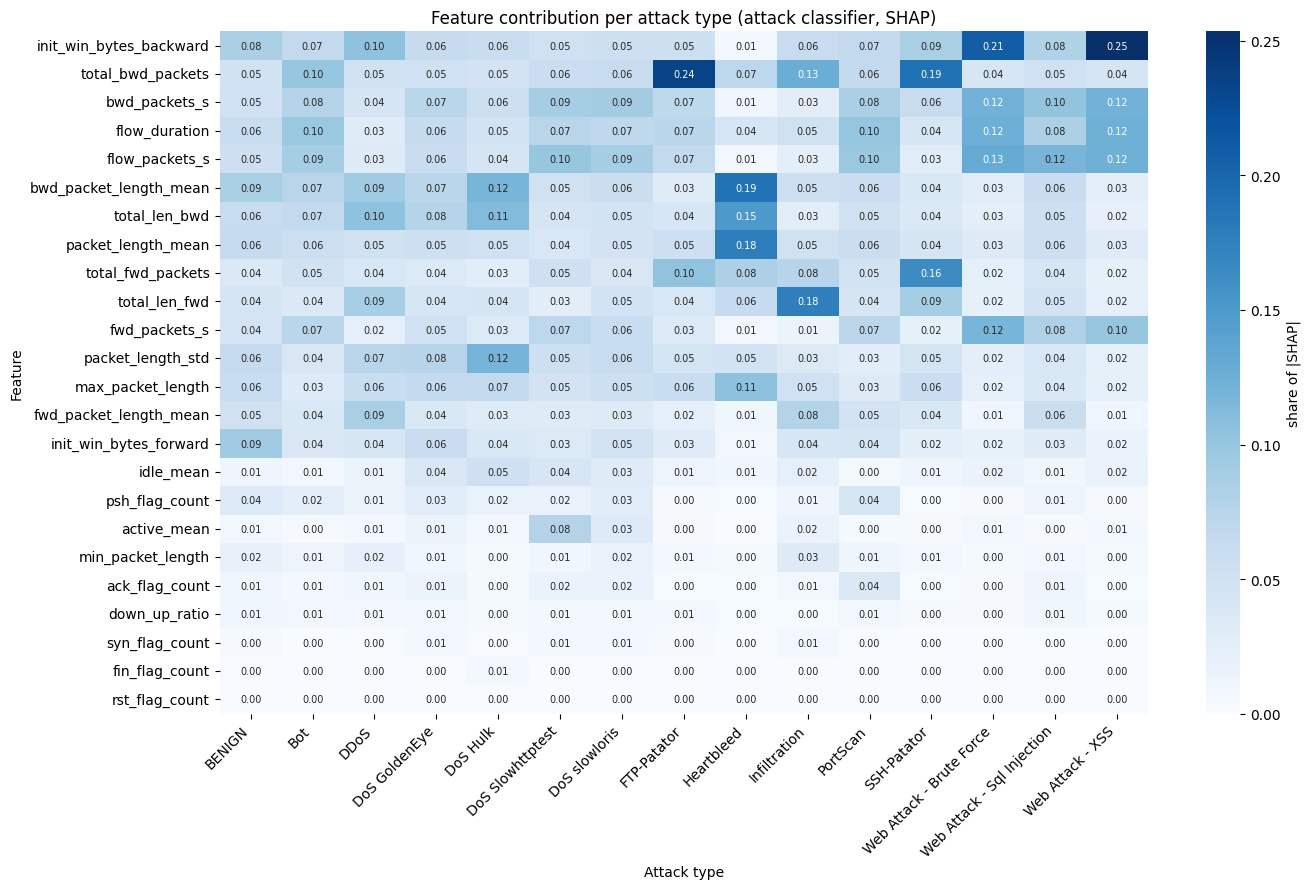

In [5]:
share = {}
for k, cls in enumerate(CLASSES):
    rows = (sample["label"] == cls).to_numpy()
    mean_abs = np.abs(clf_sv.values[rows, :, k]).mean(axis=0)
    share[cls] = mean_abs / mean_abs.sum()

share = pd.DataFrame(share, index=FEATURES)
share = share.loc[share.mean(axis=1).sort_values(ascending=False).index]

plt.figure(figsize=(14, 9))
sns.heatmap(share, cmap="Blues", annot=True, fmt=".2f", annot_kws={"size": 7}, cbar_kws={"label": "share of |SHAP|"})
plt.title("Feature contribution per attack type (attack classifier, SHAP)")
plt.xlabel("Attack type")
plt.ylabel("Feature")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(FIG_DIR / "shap_attack_type_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

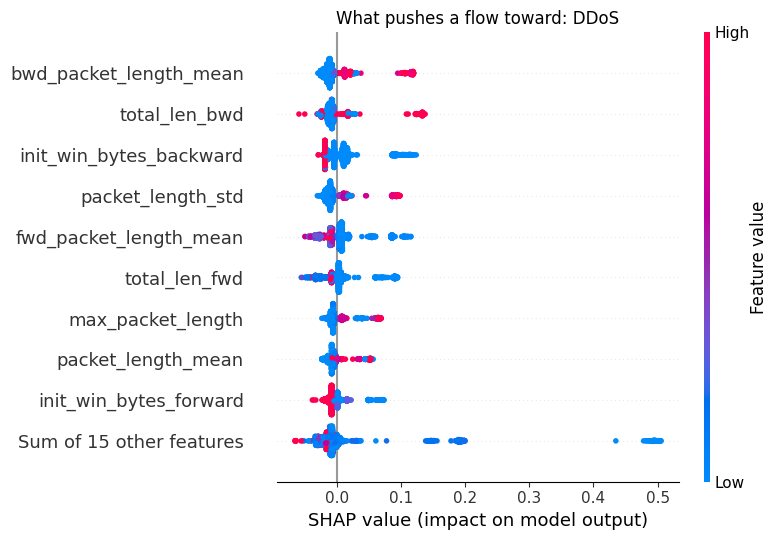

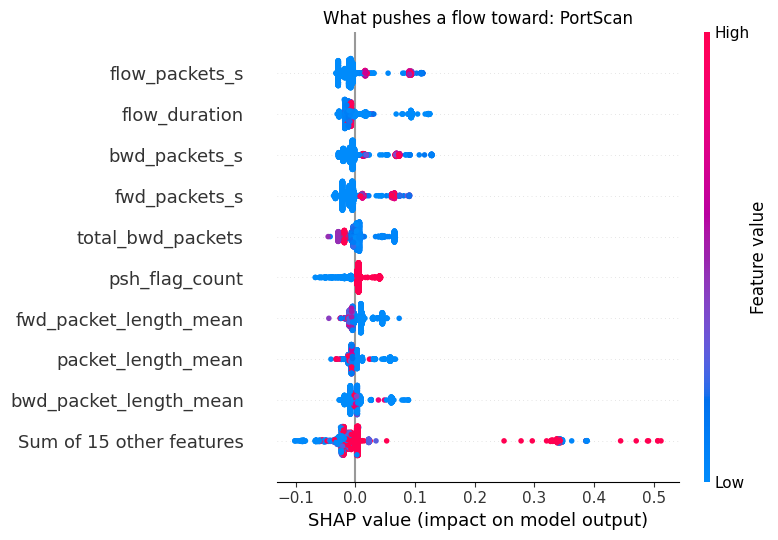

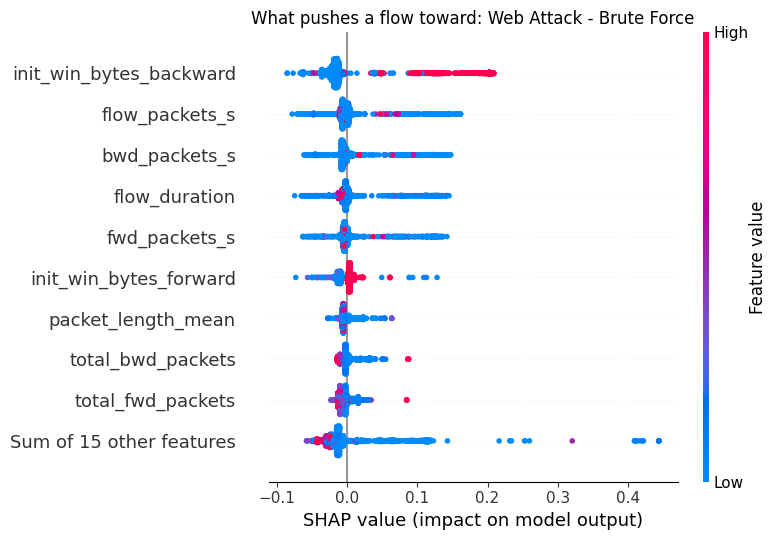

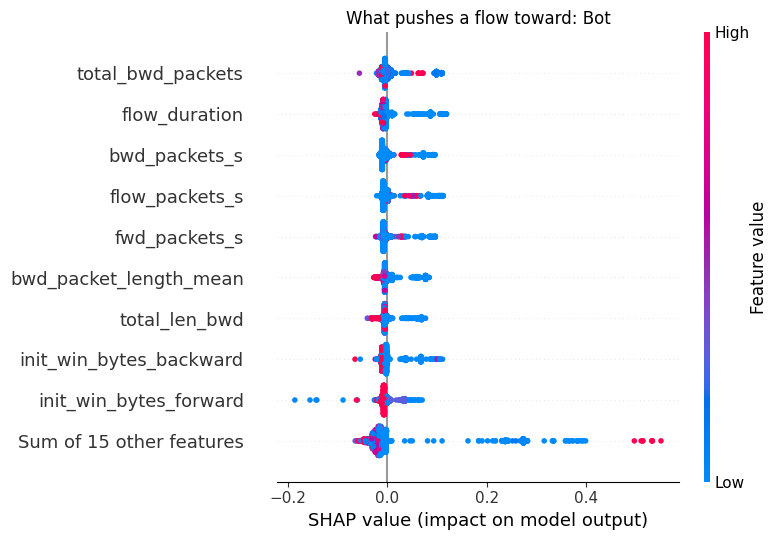

In [6]:
# Beeswarm plots: red = high feature value, blue = low; right = pushes toward the class.
for cls in ["DDoS", "PortScan", "Web Attack - Brute Force", "Bot"]:
    k = CLASSES.index(cls)
    shap.plots.beeswarm(clf_sv[:, :, k], max_display=10, show=False)
    plt.title(f"What pushes a flow toward: {cls}")
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"shap_beeswarm_{cls.replace(' ', '_').replace('-', '')}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 5. Feature reference (benign percentiles and readable names)

Lets any value be described as "higher than X% of normal traffic". Percentiles are computed from all BENIGN rows.

In [7]:
DISPLAY = {
    "flow_duration": ("Flow duration", "µs"),
    "total_fwd_packets": ("Forward packets", "packets"),
    "total_bwd_packets": ("Backward packets", "packets"),
    "total_len_fwd": ("Forward bytes", "bytes"),
    "total_len_bwd": ("Backward bytes", "bytes"),
    "flow_packets_s": ("Flow packet rate", "packets/s"),
    "fwd_packets_s": ("Forward packet rate", "packets/s"),
    "bwd_packets_s": ("Backward packet rate", "packets/s"),
    "fwd_packet_length_mean": ("Mean forward packet size", "bytes"),
    "bwd_packet_length_mean": ("Mean backward packet size", "bytes"),
    "min_packet_length": ("Minimum packet size", "bytes"),
    "max_packet_length": ("Maximum packet size", "bytes"),
    "packet_length_mean": ("Mean packet size", "bytes"),
    "packet_length_std": ("Packet size std. dev.", "bytes"),
    "syn_flag_count": ("SYN flag", ""),
    "ack_flag_count": ("ACK flag", ""),
    "rst_flag_count": ("RST flag", ""),
    "psh_flag_count": ("PSH flag", ""),
    "fin_flag_count": ("FIN flag", ""),
    "down_up_ratio": ("Download/upload ratio", ""),
    "init_win_bytes_forward": ("Initial TCP window (forward)", "bytes"),
    "init_win_bytes_backward": ("Initial TCP window (backward)", "bytes"),
    "active_mean": ("Mean active time", "µs"),
    "idle_mean": ("Mean idle time", "µs"),
}
assert set(DISPLAY) == set(FEATURES)

benign = df[df["label"] == "BENIGN"]
PCT_LEVELS = np.round(np.linspace(0, 100, 1001), 1)
benign_quantiles = {f: np.percentile(benign[f], PCT_LEVELS) for f in FEATURES}

feature_reference = {
    "description": "Benign (normal traffic) quantiles per feature, for describing a value as a percentile of normal traffic.",
    "percentile_levels": PCT_LEVELS.tolist(),
    "features": {
        f: {
            "display_name": DISPLAY[f][0],
            "unit": DISPLAY[f][1],
            "benign_median": float(benign[f].median()),
            "benign_quantiles": [round(float(v), 6) for v in benign_quantiles[f]],
        }
        for f in FEATURES
    },
}
(MODEL_DIR / "feature_reference.json").write_text(json.dumps(feature_reference))
print("Saved:", MODEL_DIR / "feature_reference.json")


def benign_percentile(feature, value):
    # Mid-rank percentile of `value` among BENIGN values (handles ties such as many zeros).
    q = benign_quantiles[feature]
    lo = np.searchsorted(q, value, side="left")
    hi = np.searchsorted(q, value, side="right")
    return float((lo + hi) / 2 / (len(q) - 1) * 100)


def fmt_value(value):
    if float(value).is_integer():
        return f"{int(value):,}"
    return f"{value:,.2f}"


def describe(feature, value):
    name, unit = DISPLAY[feature]
    pct = benign_percentile(feature, value)
    share = pct if pct >= 50 else 100 - pct
    share = min(share, 99.9)  # never claim "100% of normal traffic"
    share_txt = f"{share:.1f}%" if share >= 99 else f"{share:.0f}%"
    where = f"higher than {share_txt} of normal traffic" if pct >= 50 else f"lower than {share_txt} of normal traffic"
    return f"{name} = {fmt_value(value)}{(' ' + unit) if unit else ''} ({where})"


print(describe("flow_packets_s", 43478.26))
print(describe("flow_duration", 46))

Saved: D:\Cybersecurity-assistant\ml\models\feature_reference.json
Flow packet rate = 43,478.26 packets/s (higher than 93% of normal traffic)
Flow duration = 46 µs (lower than 94% of normal traffic)


## 6. Attack-type profiles

For each attack type: the top features by SHAP, and whether the attack's typical value is higher or lower than normal traffic.
Saved for the LLM/RAG agent to answer *"what characterises DDoS?"* from model evidence.

In [8]:
profiles = {}
for k, cls in enumerate(CLASSES):
    if cls == "BENIGN":
        continue
    rows = sample["label"] == cls
    top = share[cls].sort_values(ascending=False).head(TOP_K)

    features = []
    for f, s in top.items():
        median = float(sample.loc[rows, f].median())
        pct = benign_percentile(f, median)
        direction = "higher" if pct >= 60 else "lower" if pct <= 40 else "similar"
        features.append({
            "feature": f,
            "display_name": DISPLAY[f][0],
            "unit": DISPLAY[f][1],
            "shap_share": round(float(s), 4),
            "attack_median": median,
            "benign_median": float(benign[f].median()),
            "median_benign_percentile": round(pct, 1),
            "direction_vs_normal": direction,
        })

    summary = "; ".join(
        f"{x['display_name']} typically {x['direction_vs_normal']} than normal "
        f"(median {fmt_value(x['attack_median'])} vs {fmt_value(x['benign_median'])})"
        if x["direction_vs_normal"] != "similar"
        else f"{x['display_name']} similar to normal but distinctive in combination"
        for x in features
    )
    profiles[cls] = {"n_rows_explained": int(rows.sum()), "top_features": features, "summary": summary}

(MODEL_DIR / "attack_type_profiles.json").write_text(json.dumps(profiles, indent=2))
print("Saved:", MODEL_DIR / "attack_type_profiles.json")
print()
for cls in ["DDoS", "PortScan", "SSH-Patator", "Web Attack - XSS"]:
    print(f"{cls}: {profiles[cls]['summary']}")
    print()

Saved: D:\Cybersecurity-assistant\ml\models\attack_type_profiles.json

DDoS: Initial TCP window (backward) typically higher than normal (median 229 vs 0); Backward bytes typically higher than normal (median 11,601 vs 163); Mean backward packet size typically higher than normal (median 1,934.50 vs 95); Forward bytes typically lower than normal (median 26 vs 72); Mean forward packet size typically lower than normal (median 7.83 vs 40)

PortScan: Flow duration typically lower than normal (median 92.50 vs 61,793); Flow packet rate typically higher than normal (median 21,627.31 vs 63.92); Backward packet rate typically higher than normal (median 10,813.65 vs 18.98); Forward packet rate typically higher than normal (median 10,813.65 vs 32.35); Initial TCP window (backward) similar to normal but distinctive in combination

SSH-Patator: Backward packets typically higher than normal (median 32 vs 2); Forward packets typically higher than normal (median 21 vs 2); Forward bytes typically higher t

## 7. Global: intrusion-risk model

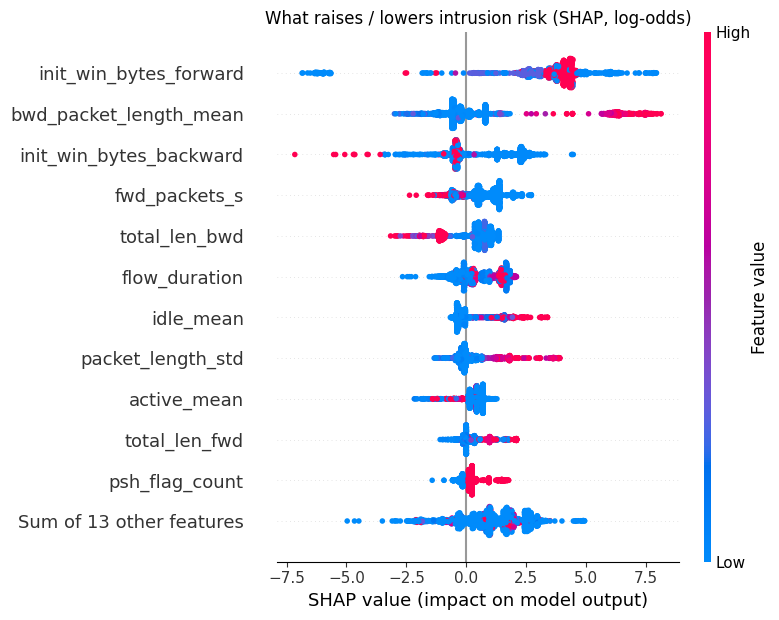

Share of total |SHAP| (risk model):
init_win_bytes_forward     0.289
bwd_packet_length_mean     0.126
init_win_bytes_backward    0.092
fwd_packets_s              0.062
total_len_bwd              0.059
flow_duration              0.056
idle_mean                  0.042
packet_length_std          0.040
active_mean                0.033
total_len_fwd              0.025


In [9]:
shap.plots.beeswarm(risk_sv, max_display=12, show=False)
plt.title("What raises / lowers intrusion risk (SHAP, log-odds)")
plt.tight_layout()
plt.savefig(FIG_DIR / "shap_risk_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

risk_importance = pd.Series(np.abs(risk_sv.values).mean(axis=0), index=FEATURES).sort_values(ascending=False)
risk_share = risk_importance / risk_importance.sum()
print("Share of total |SHAP| (risk model):")
print(risk_share.head(10).round(3).to_string())

### Reliance on `init_win_bytes_forward` (dataset artifact check)

The TCP initial window size partly reflects the attacker machines' OS settings in CIC-IDS2017 rather than attack behaviour.

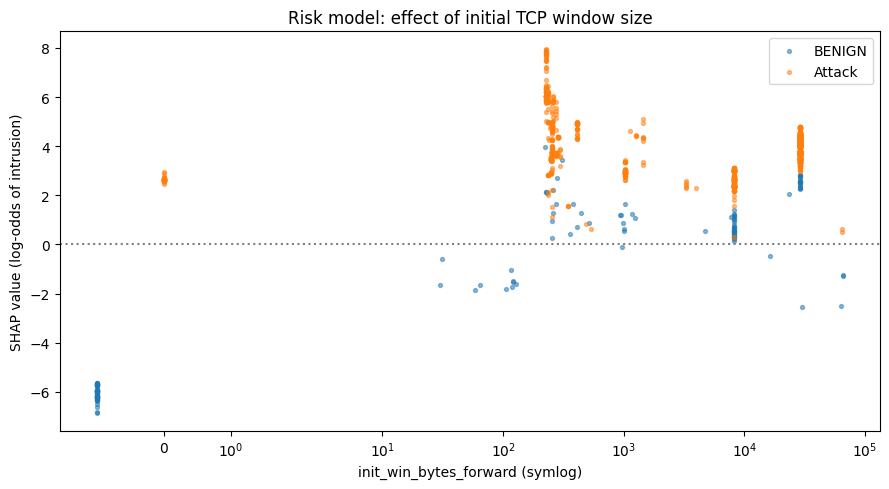

init_win_bytes_forward accounts for 28.9% of the risk model's total |SHAP|.
Top-3 features account for 50.7%.


In [10]:
is_attack = (sample["label"] != "BENIGN").to_numpy()
x = sample["init_win_bytes_forward"].to_numpy()
y = risk_sv[:, "init_win_bytes_forward"].values

plt.figure(figsize=(9, 5))
plt.scatter(x[~is_attack], y[~is_attack], s=8, alpha=0.5, label="BENIGN")
plt.scatter(x[is_attack], y[is_attack], s=8, alpha=0.5, label="Attack")
plt.xscale("symlog")
plt.axhline(0, color="grey", linestyle=":")
plt.xlabel("init_win_bytes_forward (symlog)")
plt.ylabel("SHAP value (log-odds of intrusion)")
plt.title("Risk model: effect of initial TCP window size")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "shap_risk_init_win_dependence.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"init_win_bytes_forward accounts for {risk_share['init_win_bytes_forward']:.1%} of the risk model's total |SHAP|.")
print(f"Top-3 features account for {risk_share.head(3).sum():.1%}.")

## 8. Local explanation: `explain_flow()`

Combines the three models for one flow. The `summary` is template text (no LLM); the LLM agent will rephrase it later.
This function moves to `src/services/explainer.py` when the ML service is built.

In [11]:
RISK_BANDS = sorted(risk_meta["risk_bands"].items(), key=lambda kv: kv[1], reverse=True)


def explain_flow(flow, top_k=3):
    missing = [f for f in FEATURES if f not in flow]
    if missing:
        raise ValueError(f"Missing features: {missing}")
    row = pd.DataFrame([flow])[FEATURES]
    values = row.iloc[0]

    # Attack type
    proba = clf.predict_proba(row)[0]
    k = int(np.argmax(proba))
    predicted = CLASSES[k]
    sv_cls = pd.Series(clf_explainer(row).values[0, :, k], index=FEATURES)
    type_reasons = [
        {"feature": f, "value": float(values[f]), "shap": round(float(s), 4),
         "benign_percentile": round(benign_percentile(f, values[f]), 1), "text": describe(f, values[f])}
        for f, s in sv_cls.sort_values(ascending=False).head(top_k).items() if s > 0
    ]

    # Intrusion risk
    risk_p = float(risk_model.predict_proba(row)[0, 1])
    risk_level = next(name for name, lo in RISK_BANDS if risk_p >= lo)
    sv_risk = pd.Series(risk_explainer(row).values[0], index=FEATURES)
    risk_reasons = [
        {"feature": f, "value": float(values[f]), "shap": round(float(s), 4),
         "effect": "raises risk" if s > 0 else "lowers risk", "text": describe(f, values[f])}
        for f, s in sv_risk.reindex(sv_risk.abs().sort_values(ascending=False).index).head(top_k).items()
    ]

    # Anomaly
    a_score = float(-anomaly_model.score_samples(row)[0])
    th = anomaly_meta["thresholds"]
    a_level = "High" if a_score >= th["high"] else "Medium" if a_score >= th["medium"] else "Low"
    pcts = pd.Series({f: benign_percentile(f, values[f]) for f in FEATURES})
    extremeness = (pcts - 50).abs().sort_values(ascending=False)
    unusual = [
        {"feature": f, "value": float(values[f]), "benign_percentile": round(pcts[f], 1), "text": describe(f, values[f])}
        for f in extremeness.index[:top_k] if extremeness[f] >= 45   # outside the 5th-95th benign range
    ]

    reasons_text = "; ".join(r["text"] for r in type_reasons) or "no single dominant feature"
    summary = (
        f"Classified as {predicted} ({proba[k]:.0%} confidence). "
        f"Intrusion risk {risk_p:.0%} ({risk_level}). Anomaly level {a_level}. "
        f"Main reasons: {reasons_text}."
    )
    if predicted == "BENIGN" and a_level == "High":
        summary += " Note: looks benign to the classifier but is highly unusual - possible unknown attack, review."

    return {
        "attack_type": {"prediction": predicted, "confidence": round(float(proba[k]), 4), "top_reasons": type_reasons},
        "risk": {"probability": round(risk_p, 4), "level": risk_level,
                 "is_intrusion": risk_p >= risk_meta["decision_threshold"], "top_reasons": risk_reasons},
        "anomaly": {"score": round(a_score, 4), "level": a_level, "most_unusual_features": unusual},
        "summary": summary,
    }

In [12]:
# One flow per traffic type
examples = sample.groupby("label").head(1)
for _, ex in examples.iterrows():
    result = explain_flow(ex[FEATURES].to_dict())
    print(f"[actual: {ex['label']}]")
    print(result["summary"])
    print()

[actual: BENIGN]
Classified as BENIGN (100% confidence). Intrusion risk 0% (Low). Anomaly level Low. Main reasons: Initial TCP window (forward) = 120 bytes (lower than 53% of normal traffic); Flow duration = 571 µs (lower than 77% of normal traffic); Packet size std. dev. = 3.46 bytes (lower than 75% of normal traffic).



[actual: Bot]
Classified as Bot (100% confidence). Intrusion risk 100% (Critical). Anomaly level Low. Main reasons: Backward packets = 3 packets (higher than 69% of normal traffic); Flow duration = 77,932 µs (higher than 54% of normal traffic); Flow packet rate = 89.82 packets/s (higher than 60% of normal traffic).



[actual: DDoS]
Classified as DDoS (100% confidence). Intrusion risk 100% (Critical). Anomaly level Low. Main reasons: Backward bytes = 11,607 bytes (higher than 95% of normal traffic); Mean backward packet size = 2,321.40 bytes (higher than 99.9% of normal traffic); Forward bytes = 26 bytes (lower than 76% of normal traffic).



[actual: DoS GoldenEye]
Classified as DoS GoldenEye (100% confidence). Intrusion risk 100% (Critical). Anomaly level Low. Main reasons: Backward bytes = 11,632 bytes (higher than 95% of normal traffic); Mean backward packet size = 1,661.71 bytes (higher than 99.2% of normal traffic); Packet size std. dev. = 1,581.37 bytes (higher than 99.1% of normal traffic).



[actual: DoS Hulk]
Classified as DoS Hulk (100% confidence). Intrusion risk 100% (Critical). Anomaly level Low. Main reasons: Backward bytes = 11,595 bytes (higher than 95% of normal traffic); Mean backward packet size = 1,656.43 bytes (higher than 99.2% of normal traffic); Packet size std. dev. = 1,707.08 bytes (higher than 99.3% of normal traffic).



...

[actual: PortScan]
Classified as PortScan (100% confidence). Intrusion risk 100% (Critical). Anomaly level Low. Main reasons: Flow duration = 80 µs (lower than 89% of normal traffic); Flow packet rate = 25,000 packets/s (higher than 88% of normal traffic); Backward packet rate = 12,500 packets/s (higher than 91% of normal traffic).



[actual: SSH-Patator]
Classified as SSH-Patator (100% confidence). Intrusion risk 100% (Critical). Anomaly level Low. Main reasons: Backward packets = 32 packets (higher than 97% of normal traffic); Forward packets = 23 packets (higher than 95% of normal traffic); Forward bytes = 2,008 bytes (higher than 93% of normal traffic).



[actual: Web Attack - Brute Force]
Classified as Web Attack - Brute Force (95% confidence). Intrusion risk 87% (High). Anomaly level Low. Main reasons: Initial TCP window (backward) = 28,960 bytes (higher than 94% of normal traffic); Flow packet rate = 0.69 packets/s (lower than 85% of normal traffic); Backward packet rate = 0.17 packets/s (lower than 82% of normal traffic).



[actual: Web Attack - Sql Injection]
Classified as Web Attack - Sql Injection (66% confidence). Intrusion risk 98% (Critical). Anomaly level Low. Main reasons: Flow packet rate = 1.99 packets/s (lower than 77% of normal traffic); Flow duration = 5,016,759 µs (higher than 75% of normal traffic); Mean forward packet size = 119.80 bytes (higher than 91% of normal traffic).



[actual: Web Attack - XSS]
Classified as Web Attack - XSS (69% confidence). Intrusion risk 86% (High). Anomaly level Low. Main reasons: Initial TCP window (backward) = 28,960 bytes (higher than 94% of normal traffic); Flow duration = 5,262,915 µs (higher than 76% of normal traffic); Backward packet rate = 0.19 packets/s (lower than 80% of normal traffic).



In [13]:
# Full structured output for one example
print(json.dumps(explain_flow(examples[examples["label"] == "DDoS"].iloc[0][FEATURES].to_dict()), indent=2))

{
  "attack_type": {
    "prediction": "DDoS",
    "confidence": 1.0,
    "top_reasons": [
      {
        "feature": "total_len_bwd",
        "value": 11607.0,
        "shap": 0.1333,
        "benign_percentile": 95.1,
        "text": "Backward bytes = 11,607 bytes (higher than 95% of normal traffic)"
      },
      {
        "feature": "bwd_packet_length_mean",
        "value": 2321.4,
        "shap": 0.1185,
        "benign_percentile": 100.0,
        "text": "Mean backward packet size = 2,321.40 bytes (higher than 99.9% of normal traffic)"
      },
      {
        "feature": "total_len_fwd",
        "value": 26.0,
        "shap": 0.0937,
        "benign_percentile": 23.7,
        "text": "Forward bytes = 26 bytes (lower than 76% of normal traffic)"
      }
    ]
  },
  "risk": {
    "probability": 1.0,
    "level": "Critical",
    "is_intrusion": true,
    "top_reasons": [
      {
        "feature": "bwd_packet_length_mean",
        "value": 2321.4,
        "shap": 7.1682,
        

## 9. Test `explain_flow()` with your own input

**Quick manual test (about 10 seconds, no need to run the whole notebook):**
run these cells in order:
1. the imports cell at the top
2. **1. Load models and data**
3. **5. Feature reference** (the `DISPLAY = {...}` cell)
4. **8. Local explanation** (the `def explain_flow` cell only)
5. the two cells below: edit `custom_flow`, then run the result cell

Ways to build an input:
- edit the values in `custom_flow` (all 24 features are required)
- take a real flow: `custom_flow = df[df["label"] == "DDoS"].iloc[0][FEATURES].to_dict()`
- start from a real flow and change one value to see how the explanation reacts, e.g. `custom_flow["flow_packets_s"] = 5`

In [14]:
# Edit any value below. The example is a real PortScan flow from CIC-IDS2017.
custom_flow = {
    "flow_duration": 46.0,
    "total_fwd_packets": 1.0,
    "total_bwd_packets": 1.0,
    "total_len_fwd": 2.0,
    "total_len_bwd": 6.0,
    "flow_packets_s": 43478.26087,
    "fwd_packets_s": 21739.13043,
    "bwd_packets_s": 21739.13043,
    "fwd_packet_length_mean": 2.0,
    "bwd_packet_length_mean": 6.0,
    "min_packet_length": 2.0,
    "max_packet_length": 6.0,
    "packet_length_mean": 3.333333,
    "packet_length_std": 2.309401,
    "syn_flag_count": 0.0,
    "ack_flag_count": 0.0,
    "rst_flag_count": 0.0,
    "psh_flag_count": 1.0,
    "fin_flag_count": 0.0,
    "down_up_ratio": 1.0,
    "init_win_bytes_forward": 1024.0,
    "init_win_bytes_backward": 0.0,
    "active_mean": 0.0,
    "idle_mean": 0.0,
}

In [15]:
result = explain_flow(custom_flow)

print(result["summary"])
print()
print(json.dumps(result, indent=2))  # full structured output

Classified as PortScan (100% confidence). Intrusion risk 98% (Critical). Anomaly level Low. Main reasons: Flow duration = 46 µs (lower than 94% of normal traffic); Flow packet rate = 43,478.26 packets/s (higher than 93% of normal traffic); Backward packet rate = 21,739.13 packets/s (higher than 96% of normal traffic).

{
  "attack_type": {
    "prediction": "PortScan",
    "confidence": 1.0,
    "top_reasons": [
      {
        "feature": "flow_duration",
        "value": 46.0,
        "shap": 0.0923,
        "benign_percentile": 6.5,
        "text": "Flow duration = 46 \u00b5s (lower than 94% of normal traffic)"
      },
      {
        "feature": "flow_packets_s",
        "value": 43478.26087,
        "shap": 0.0904,
        "benign_percentile": 92.8,
        "text": "Flow packet rate = 43,478.26 packets/s (higher than 93% of normal traffic)"
      },
      {
        "feature": "bwd_packets_s",
        "value": 21739.13043,
        "shap": 0.0735,
        "benign_percentile": 95.9,
 

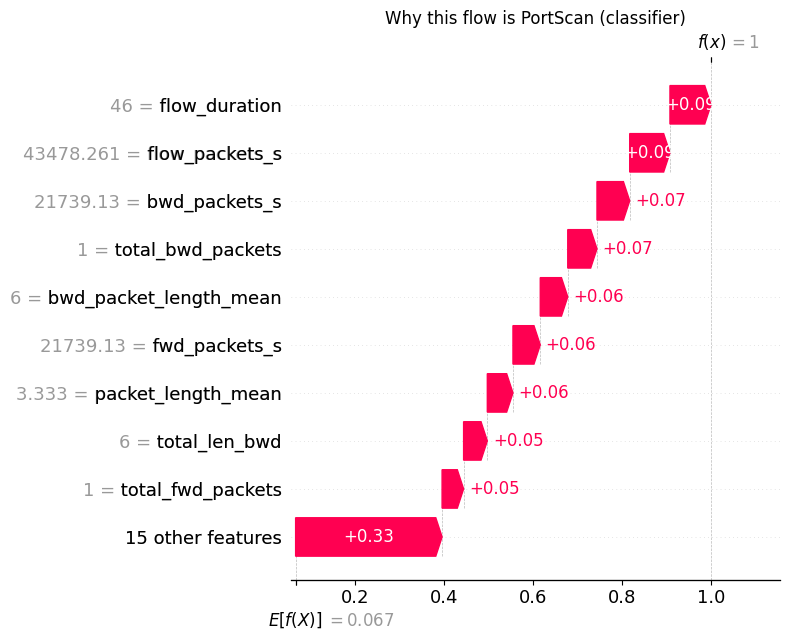

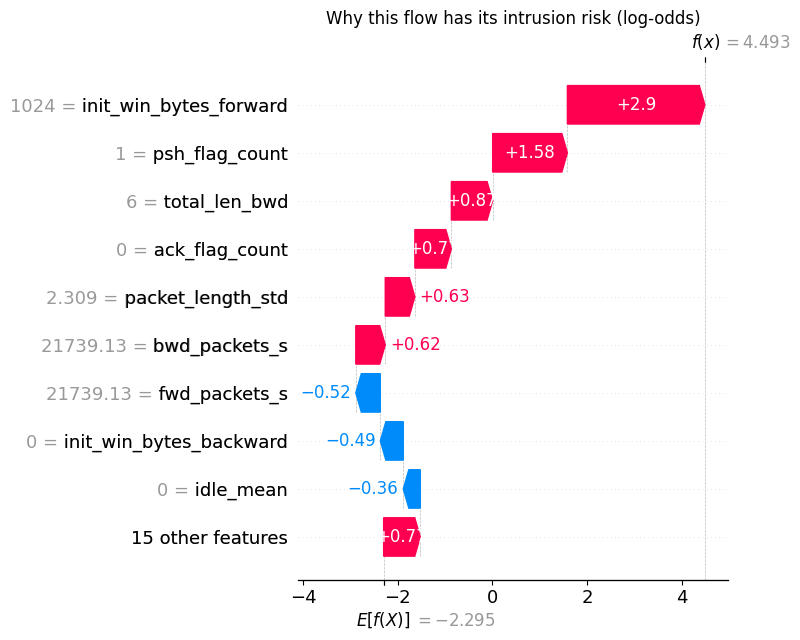

In [16]:
row = pd.DataFrame([custom_flow])[FEATURES]
k = CLASSES.index(result["attack_type"]["prediction"])

shap.plots.waterfall(clf_explainer(row)[0, :, k], max_display=10, show=False)
plt.title(f"Why this flow is {CLASSES[k]} (classifier)")
plt.tight_layout()
plt.savefig(FIG_DIR / "shap_waterfall_classifier_example.png", dpi=150, bbox_inches="tight")
plt.show()

shap.plots.waterfall(risk_explainer(row)[0], max_display=10, show=False)
plt.title("Why this flow has its intrusion risk (log-odds)")
plt.tight_layout()
plt.savefig(FIG_DIR / "shap_waterfall_risk_example.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Saved outputs

In [17]:
for p in [MODEL_DIR / "attack_type_profiles.json", MODEL_DIR / "feature_reference.json", *sorted(FIG_DIR.glob("shap_*.png"))]:
    print(f"{p.relative_to(PROJECT_ROOT)}  ({p.stat().st_size / 1024:.0f} KB)")

ml\models\attack_type_profiles.json  (28 KB)
ml\models\feature_reference.json  (173 KB)
ml\reports\figures\shap_attack_type_heatmap.png  (327 KB)
ml\reports\figures\shap_beeswarm_Bot.png  (98 KB)
ml\reports\figures\shap_beeswarm_DDoS.png  (104 KB)
ml\reports\figures\shap_beeswarm_PortScan.png  (103 KB)
ml\reports\figures\shap_beeswarm_Web_Attack__Brute_Force.png  (110 KB)
ml\reports\figures\shap_risk_beeswarm.png  (140 KB)
ml\reports\figures\shap_risk_init_win_dependence.png  (55 KB)
ml\reports\figures\shap_waterfall_classifier_example.png  (95 KB)
ml\reports\figures\shap_waterfall_risk_example.png  (92 KB)
